# Q1 · Part B — Multiple linear regression from scratch (NumPy only)

**What this notebook does:** feature scaling → hypothesis → regularised cost → gradient descent → convergence plot →
final $\theta$ → comparison with scikit-learn `LinearRegression` (MSE).

> **Before running:** put the dataset CSV (link in the exam paper) into `data/q1/`.
> If the target is not the last column, set `TARGET_COL` below.

In [1]:
# ---- Project setup: finds the project root automatically ----
import os, sys, json, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

def find_root():
    start = Path(os.environ.get("LAB_ROOT", Path.cwd())).resolve()
    for p in [start, *start.parents]:
        if (p / "requirements.txt").exists() and (p / "src").exists():
            return p
    raise RuntimeError("Project root not found. Open this notebook from inside the Prog_for_AI_Lab folder.")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "src"))
print("Project root:", ROOT)

Project root: C:\Users\hp\Desktop\Prog_for_AI_Lab\Prog_for_AI_Lab


In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from lab_utils import save_json, savefig
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 1. Configuration (the choices you must justify in the report)

In [3]:
DATA_FILE   = None      # e.g. "data.csv"; None = first csv/xlsx file found in data/q1
TARGET_COL  = None      # None = last column is the target y
DROP_COLS   = []        # ID-like columns to ignore, e.g. ["Unnamed: 0", "id"]

TEST_SIZE   = 0.20      # 80 % train / 20 % test
SEED        = 42
SCALING     = "standard"   # "standard" (z-score) or "minmax"
ALPHA       = 0.1          # learning rate
LAMBDA      = 1.0          # regularisation strength
N_ITERS     = 2000         # gradient-descent iterations

## 2. Load the data

In [4]:
from linreg_scratch import load_regression_data
X_df, y_s, path, raw = load_regression_data(ROOT / "data" / "q1", DATA_FILE, TARGET_COL, DROP_COLS)
print("File:", path.name, "| rows:", len(X_df), "| features:", X_df.shape[1], "| target:", y_s.name)
display(raw.head())
display(X_df.describe().T)
print("Missing values in raw file:", int(raw.isna().sum().sum()))

File: multiple_linear_regression_dataset.csv | rows: 20 | features: 2 | target: income


,age,experience,income
0,25,1,30450
1,30,3,35670
2,47,2,31580
3,32,5,40130
4,43,10,47830


,count,mean,std,min,25%,50%,75%,max
age,20.0,39.65,10.027725,23.0,31.50,40.0,47.0,58.0
experience,20.0,6.20,4.124382,1.0,3.75,5.0,9.0,17.0


Missing values in raw file: 0


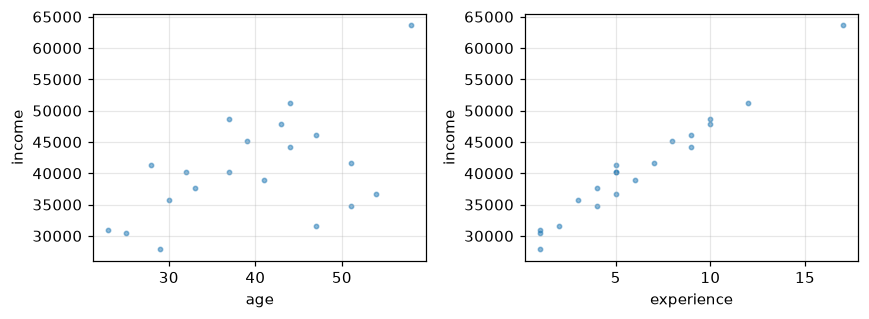

In [5]:
# Quick look: relationship of each feature with the target
n_f = X_df.shape[1]
cols = min(n_f, 4); rows = int(np.ceil(n_f / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows), squeeze=False)
for ax, c in zip(axes.ravel(), X_df.columns):
    ax.scatter(X_df[c], y_s, s=8, alpha=0.5); ax.set_xlabel(c); ax.set_ylabel(y_s.name)
for ax in axes.ravel()[n_f:]: ax.axis("off")
plt.tight_layout(); savefig(fig, "q1", "eda_scatter"); plt.show()

## 3. Train / test split
The split is done **before** scaling, so the test set never influences the scaling parameters.

In [6]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_df.values.astype(float), y_s.values.astype(float), test_size=TEST_SIZE, random_state=SEED)
print("train:", X_train_raw.shape, " test:", X_test_raw.shape)

train: (16, 2)  test: (4, 2)


## 4. Feature scaling (from scratch)
Gradient descent converges much faster when all features are on a similar scale.

In [7]:
def fit_scaler(X, method="standard"):
    """Learn the scaling parameters from the TRAINING data only (avoids data leakage)."""
    X = np.asarray(X, dtype=float)
    if method == "standard":            # z-score: (x - mean) / std
        center, scale = X.mean(axis=0), X.std(axis=0)
    elif method == "minmax":            # (x - min) / (max - min)
        center, scale = X.min(axis=0), X.max(axis=0) - X.min(axis=0)
    elif method == "none":              # no scaling (used only for the experiment)
        center, scale = np.zeros(X.shape[1]), np.ones(X.shape[1])
    else:
        raise ValueError("method must be 'standard', 'minmax' or 'none'")
    scale = np.where(scale == 0, 1.0, scale)   # protect against constant columns
    return {"method": method, "center": center, "scale": scale}


def apply_scaler(X, scaler):
    """Apply already-learned scaling parameters (works for train AND test data)."""
    return (np.asarray(X, dtype=float) - scaler["center"]) / scaler["scale"]


def add_bias(X):
    """Prepend the column x0 = 1 so that theta_0 is handled like every other theta_j."""
    return np.hstack([np.ones((X.shape[0], 1)), X])

In [8]:
scaler = fit_scaler(X_train_raw, SCALING)          # learn mean/std (or min/max) from TRAIN only
X_train = add_bias(apply_scaler(X_train_raw, scaler))
X_test  = add_bias(apply_scaler(X_test_raw,  scaler))
print("Scaled train means (should be ~0 for 'standard'):", np.round(X_train[:, 1:].mean(axis=0), 3))
print("Scaled train stds  (should be ~1 for 'standard'):", np.round(X_train[:, 1:].std(axis=0), 3))

Scaled train means (should be ~0 for 'standard'): [0. 0.]
Scaled train stds  (should be ~1 for 'standard'): [1. 1.]


## 5. Hypothesis and regularised cost function

In [9]:
def hypothesis(X_b, theta):
    """h_theta(x) = theta_0 + theta_1 x_1 + ... + theta_n x_n   (vectorised: X_b @ theta)."""
    return X_b @ theta


def cost_function(X_b, y, theta, lam=0.0):
    """J(theta) = 1/(2m) * [ sum (h - y)^2 + lambda * sum_{j>=1} theta_j^2 ]  (theta_0 NOT regularised)."""
    m = len(y)
    errors = hypothesis(X_b, theta) - y
    reg_term = lam * np.sum(theta[1:] ** 2)
    return (np.sum(errors ** 2) + reg_term) / (2 * m)

## 6. Gradient and gradient descent
The gradient is the *vector form* derived in notebook 01. Below we also prove that the *component form* gives the same numbers.

In [10]:
def gradient(X_b, y, theta, lam=0.0):
    """Vector form of dJ/dtheta:  (1/m) * [ X^T (X theta - y) + lambda * theta_tilde ],  theta_tilde = [0, theta_1..theta_n]."""
    m = len(y)
    errors = hypothesis(X_b, theta) - y
    grad = (X_b.T @ errors) / m          # j = 0 and the data part of j >= 1
    grad[1:] += (lam / m) * theta[1:]    # regularisation part (only for j >= 1)
    return grad


def gradient_descent(X_b, y, alpha=0.1, lam=0.0, n_iters=2000, theta0=None, tol=0.0):
    """Batch gradient descent. Returns (theta, cost_history)."""
    m, n_plus_1 = X_b.shape
    theta = np.zeros(n_plus_1) if theta0 is None else np.array(theta0, dtype=float)
    history = []
    with np.errstate(all="ignore"):
        for it in range(n_iters):
            cost = cost_function(X_b, y, theta, lam)
            history.append(cost)
            if not np.isfinite(cost) or cost > 1e30:        # diverged -> stop early
                break
            if tol and it > 0 and abs(history[-2] - cost) < tol:   # converged
                break
            theta = theta - alpha * gradient(X_b, y, theta, lam)   # simultaneous update of all theta_j
    return theta, np.array(history)

In [11]:
def mse(y_true, y_pred):
    """Mean Squared Error = mean((y - y_hat)^2)   (this is NOT the same as J(theta))."""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return float(np.mean((y_true - y_pred) ** 2))


def r2_score_manual(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return float(1 - ss_res / ss_tot)


def normal_equation(X_b, y, lam=0.0):
    """Closed-form solution theta = (X^T X + lambda * L)^-1 X^T y, L = identity with L[0,0] = 0.
    Used only to VERIFY that gradient descent reached the true minimum."""
    n_plus_1 = X_b.shape[1]
    L = np.eye(n_plus_1)
    L[0, 0] = 0.0
    return np.linalg.solve(X_b.T @ X_b + lam * L, X_b.T @ y)


def theta_to_original_units(theta, scaler):
    """Convert theta learned on scaled features back to the original feature units
    (so it can be compared directly with scikit-learn's intercept_ and coef_)."""
    coefs = theta[1:] / scaler["scale"]
    intercept = theta[0] - np.sum(theta[1:] * scaler["center"] / scaler["scale"])
    return np.concatenate([[intercept], coefs])

In [12]:
# Proof that component form == vector form (one update step, written with explicit loops)
def update_component_form(X_b, y, theta, alpha, lam):
    m, n1 = X_b.shape
    new_theta = theta.copy()
    for j in range(n1):
        s = 0.0
        for i in range(m):
            s += (X_b[i] @ theta - y[i]) * X_b[i, j]
        if j == 0:
            new_theta[j] = theta[j] - (alpha / m) * s
        else:
            new_theta[j] = theta[j] - (alpha / m) * (s + lam * theta[j])
    return new_theta

t0 = np.random.default_rng(1).normal(size=X_train.shape[1])
step_vec = t0 - ALPHA * gradient(X_train, y_train, t0, LAMBDA)
step_cmp = update_component_form(X_train[:100], y_train[:100], t0, ALPHA, LAMBDA)
step_vec100 = t0 - ALPHA * gradient(X_train[:100], y_train[:100], t0, LAMBDA)
print("vector form  :", np.round(step_vec100, 6))
print("component form:", np.round(step_cmp, 6))
print("identical:", np.allclose(step_vec100, step_cmp))

vector form  : [4242.936026  305.973736  805.64698 ]
component form: [4242.936026  305.973736  805.64698 ]
identical: True


## 7. Train the model

In [13]:
t = time.perf_counter()
theta, history = gradient_descent(X_train, y_train, alpha=ALPHA, lam=LAMBDA, n_iters=N_ITERS)
gd_time = time.perf_counter() - t
print(f"Finished {len(history)} iterations in {gd_time:.3f}s")
print(f"Initial cost J = {history[0]:.4f}   ->   final cost J = {history[-1]:.4f}")

Finished 2000 iterations in 0.203s
Initial cost J = 933602325.0000   ->   final cost J = 2953974.0659


### Convergence curve (cost vs iterations)

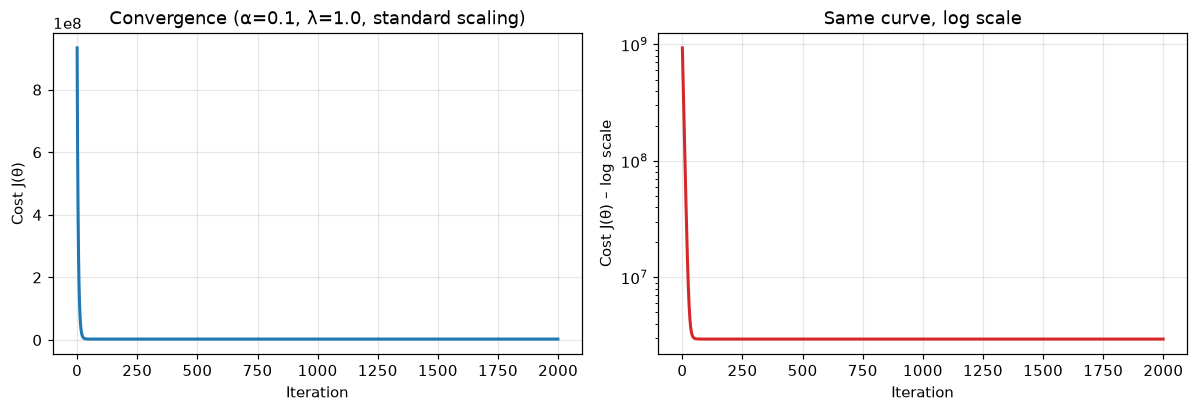

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history, lw=2); axes[0].set_xlabel("Iteration"); axes[0].set_ylabel("Cost J(θ)")
axes[0].set_title(f"Convergence (α={ALPHA}, λ={LAMBDA}, {SCALING} scaling)")
axes[1].semilogy(history, lw=2, color="tab:red"); axes[1].set_xlabel("Iteration"); axes[1].set_ylabel("Cost J(θ) – log scale")
axes[1].set_title("Same curve, log scale")
plt.tight_layout(); savefig(fig, "q1", "convergence"); plt.show()

### Final values of θ

In [15]:
feature_names = ["theta_0 (intercept)"] + [f"theta_{j+1} ({c})" for j, c in enumerate(X_df.columns)]
theta_table = pd.DataFrame({"parameter": feature_names, "theta (scaled space)": theta})
display(theta_table)

,parameter,theta (scaled space)
0,theta_0 (intercept),42426.250000
1,theta_1 (age),-550.541078
2,theta_2 (experience),7821.127206


## 8. Verify with the closed-form solution
If gradient descent converged, it must reach the same θ as the normal equation.

In [16]:
theta_closed = normal_equation(X_train, y_train, LAMBDA)
print("max |theta_GD - theta_closed_form| =", np.max(np.abs(theta - theta_closed)))

max |theta_GD - theta_closed_form| = 2.9103830456733704e-11


## 9. Compare with scikit-learn `LinearRegression`
scikit-learn's model has **no regularisation**, so we compare against our model with the chosen λ **and** with λ = 0 (a fair like-for-like test).

In [17]:
# Our model with lambda = 0 (like-for-like with sklearn)
theta_l0, hist_l0 = gradient_descent(X_train, y_train, alpha=ALPHA, lam=0.0, n_iters=N_ITERS)

# scikit-learn on the SAME scaled data
t = time.perf_counter()
sk = LinearRegression().fit(X_train[:, 1:], y_train)
sk_time = time.perf_counter() - t

preds = {
    f"Ours (GD, λ={LAMBDA})": (X_train @ theta,    X_test @ theta),
    "Ours (GD, λ=0)":         (X_train @ theta_l0, X_test @ theta_l0),
    "scikit-learn LinearRegression": (sk.predict(X_train[:, 1:]), sk.predict(X_test[:, 1:])),
}
rows = []
for name, (ptr, pte) in preds.items():
    rows.append({"model": name,
                 "train MSE": mse(y_train, ptr), "test MSE": mse(y_test, pte),
                 "test R²": r2_score_manual(y_test, pte)})
cmp_df = pd.DataFrame(rows)
display(cmp_df.style.format({"train MSE": "{:.6g}", "test MSE": "{:.6g}", "test R²": "{:.5f}"}))

# cross-check our MSE implementation against sklearn's
assert np.isclose(cmp_df.iloc[2]["test MSE"], mean_squared_error(y_test, sk.predict(X_test[:, 1:])))

,model,train MSE,test MSE,test R²
0,"Ours (GD, λ=1.0)",2.06588e+06,990779,0.91944
1,"Ours (GD, λ=0)",1.73951e+06,753797,0.93871
2,scikit-learn LinearRegression,1.73951e+06,753797,0.93871


In [18]:
# Compare parameters in ORIGINAL feature units (undo the scaling)
th_orig    = theta_to_original_units(theta, scaler)
th_l0_orig = theta_to_original_units(theta_l0, scaler)
sk_orig    = np.concatenate([[sk.intercept_], sk.coef_]) if SCALING == "none" else None
# sklearn fitted on scaled data -> convert the same way
sk_theta_scaled = np.concatenate([[sk.intercept_], sk.coef_])
sk_theta_orig   = theta_to_original_units(sk_theta_scaled, scaler)

names = ["intercept"] + list(X_df.columns)
param_df = pd.DataFrame({"parameter": names, f"Ours λ={LAMBDA}": th_orig,
                         "Ours λ=0": th_l0_orig, "scikit-learn": sk_theta_orig})
display(param_df)

,parameter,Ours λ=1.0,Ours λ=0,scikit-learn
0,intercept,31015.611058,31465.056419,31465.056419
1,age,-62.899728,-101.059234,-101.059234
2,experience,1990.837521,2154.805493,2154.805493


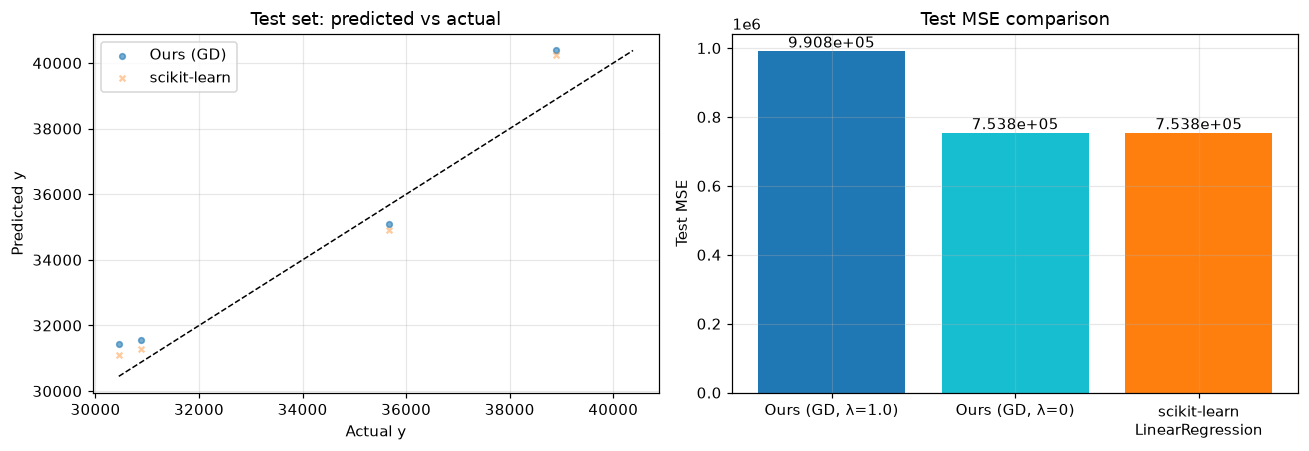

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
# predicted vs actual on the test set
lo, hi = float(min(y_test.min(), (X_test @ theta).min())), float(max(y_test.max(), (X_test @ theta).max()))
axes[0].scatter(y_test, X_test @ theta, s=14, alpha=0.6, label="Ours (GD)")
axes[0].scatter(y_test, sk.predict(X_test[:, 1:]), s=14, alpha=0.4, marker="x", label="scikit-learn")
axes[0].plot([lo, hi], [lo, hi], "k--", lw=1); axes[0].set_xlabel("Actual y"); axes[0].set_ylabel("Predicted y")
axes[0].set_title("Test set: predicted vs actual"); axes[0].legend()
# bar chart of test MSE
axes[1].bar([n.replace(" LinearRegression", "\nLinearRegression") for n in cmp_df["model"]], cmp_df["test MSE"],
            color=["tab:blue", "tab:cyan", "tab:orange"])
axes[1].set_ylabel("Test MSE"); axes[1].set_title("Test MSE comparison")
for i, v in enumerate(cmp_df["test MSE"]): axes[1].text(i, v, f"{v:.4g}", ha="center", va="bottom")
plt.tight_layout(); savefig(fig, "q1", "comparison"); plt.show()

## 10. Save everything for the report

In [ ]:
results = {
    "dataset": {"file": path.name, "rows": int(len(X_df)), "n_features": int(X_df.shape[1]),
                "features": list(map(str, X_df.columns)), "target": str(y_s.name),
                "n_train": int(len(y_train)), "n_test": int(len(y_test))},
    "config": {"scaling": SCALING, "alpha": ALPHA, "lambda": LAMBDA, "n_iters": N_ITERS,
               "test_size": TEST_SIZE, "seed": SEED},
    "gd": {"iterations_run": int(len(history)), "initial_cost": float(history[0]), "final_cost": float(history[-1]),
           "time_s": float(gd_time), "max_diff_vs_closed_form": float(np.max(np.abs(theta - theta_closed)))},
    "theta_scaled": dict(zip(["intercept"] + list(map(str, X_df.columns)), map(float, theta))),
    "theta_original_units": dict(zip(names, map(float, th_orig))),
    "theta_lambda0_original_units": dict(zip(names, map(float, th_l0_orig))),
    "theta_sklearn_original_units": dict(zip(names, map(float, sk_theta_orig))),
    "metrics": {row["model"]: {"train_mse": float(row["train MSE"]), "test_mse": float(row["test MSE"]),
                               "test_r2": float(row["test R²"])} for _, row in cmp_df.iterrows()},
    "sklearn_time_s": float(sk_time),
}
save_json(results, ROOT / "results" / "q1" / "results.json")
print("Saved results/q1/results.json  ✔  — next: run 03_Q1_Experiments.ipynb")

Saved results/q1/results.json  ✔  — next: run 03_Q1_Experiments.ipynb


: 